# 06 · Rating Elo dos times (D15)

Elo clássico sobre o resultado da **série** (vitória 1, empate 0,5 no formato "2 maps"), em ordem
temporal, implementado em `pipeline/elo.py` e materializado pelo Python model `fct_team_elo`. O
rating usado para prever uma partida é sempre o de **antes** dela (`assert_no_future_leakage`).

Parâmetros:

- **K**: o quanto cada resultado move o rating;
- **rating inicial por tier**: time de VCT começa acima do de VCL (os circuitos quase não se cruzam,
  e o Elo não teria como descobrir a diferença sozinho);
- **peso do K por tier**;
- **carry de temporada**: fração do desvio ao rating inicial que atravessa a virada de temporada
  (elencos mudam no off-season).
- **reancoragem na promoção**: no primeiro jogo de VCT de um time que começou na VCL, só uma fração
  do desvio dele ao rating inicial da VCL entra no VCT. A VCL é um pool quase fechado: dominar a VCL
  infla o rating sem referência ao VCT, e em 2026 os melhores da VCL foram ao Stage 2.

Os valores saem de uma busca em grade pela **log loss das probabilidades pré-partida**, percorrendo
as partidas em ordem — avaliação sequencial, não treino de modelo. As partidas anteriores à janela
servem de aquecimento.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
import itertools
from pipeline.elo import EloParams, log_loss, run_elo

matches = con.sql("select * from main_intermediate.int_elo_matches").df()
records = matches.to_dict("records")
coin = np.log(2)

def score(**kw):
    rows = run_elo(records, EloParams(**kw))
    return log_loss(rows[::2])  # uma linha por partida: a do time 1

grid = []
for k, gap, carry, vcl_w, promo in itertools.product(
    [24, 32, 40, 48, 56, 64], [0, 100, 200, 300], [0.5, 0.75, 1.0], [0.75, 1.0],
    [None, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5],  # None: sem reancoragem na promoção
):
    grid.append({"k": k, "gap": gap, "carry": carry, "vcl_k_weight": vcl_w, "promotion_carry": promo,
                 "log_loss": score(k=k, k_by_tier={1: 1.0, 2: vcl_w},
                                   initial_by_tier={1: 1500.0 + gap / 2, 2: 1500.0 - gap / 2},
                                   season_carry=carry, promotion_carry=promo)})
grid = pd.DataFrame(grid).sort_values("log_loss")
print(f"{len(records)} partidas; moeda: {coin:.4f}; padrão do projeto: {score():.4f}")
grid.head(10)

5780 partidas; moeda: 0.6931; padrão do projeto: 0.6630


,k,gap,carry,vcl_k_weight,promotion_carry,log_loss
653,48,300,0.75,1.0,0.1,0.663
652,48,300,0.75,1.0,0.0,0.663
654,48,300,0.75,1.0,0.2,0.663
655,48,300,0.75,1.0,0.3,0.663
821,56,300,0.75,1.0,0.1,0.663
820,56,300,0.75,1.0,0.0,0.663
611,48,200,0.75,1.0,0.1,0.663
610,48,200,0.75,1.0,0.0,0.663
822,56,300,0.75,1.0,0.2,0.663
612,48,200,0.75,1.0,0.2,0.663


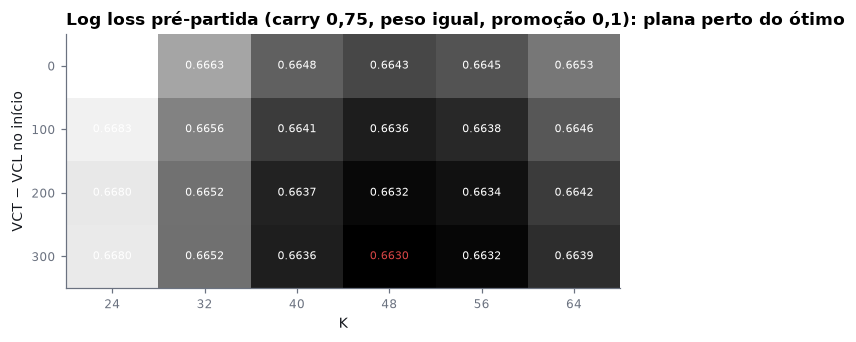

In [3]:
sub = grid[(grid.carry == 0.75) & (grid.vcl_k_weight == 1.0) & (grid.promotion_carry == 0.1)]
heat = sub.pivot(index="gap", columns="k", values="log_loss")
fig, ax = plt.subplots(figsize=(6.5, 3))
im = ax.imshow(heat.values, cmap="Greys_r", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.4f}", ha="center", va="center", fontsize=7,
                color=P.ATTACK if heat.values[i, j] == heat.values.min() else "white")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("K")
ax.set_ylabel("VCT − VCL no início")
ax.grid(False)
ax.set_title("Log loss pré-partida (carry 0,75, peso igual, promoção 0,1): plana perto do ótimo")
plt.show()

## A promoção da VCL ao VCT

Em 2026, os melhores times da VCL de cada região jogaram o Stage 2 do VCT. Sem ajuste, eles chegavam
com o rating de quem dominou a VCL: a Enterprise entrou com mais do que qualquer time do VCT depois
de 39–4 na VCL, e o ranking a punha em 2º com 6 séries de VCT. A reancoragem leva para o VCT só uma
fração do desvio da VCL. Abaixo, a log loss pré-partida antes (parâmetros até 15/10, sem
reancoragem) e depois, com o IC 95% da diferença por bootstrap pareado: as mesmas séries, as duas
previsões.

In [4]:
from pipeline.stats import mean_bootstrap

before_params = EloParams(initial_by_tier={1: 1600.0, 2: 1400.0}, promotion_carry=None)  # até 15/10
rows_before, rows_now = run_elo(records, before_params), run_elo(records, EloParams())

def match_loss(rows):
    """Log loss de cada série (linha do time 1), por match_id."""
    out = {}
    for r in rows[::2]:
        p = min(max(r["expected_result"], 1e-12), 1 - 1e-12)
        out[r["match_id"]] = -(r["result"] * np.log(p) + (1 - r["result"]) * np.log(1 - p))
    return pd.Series(out)

loss_before, loss_now = match_loss(rows_before), match_loss(rows_now)
by_match = matches.assign(match_id=matches.match_id.astype(str)).set_index("match_id")
first_tier = {}
for m in sorted(records, key=lambda m: (m["match_at"], str(m["match_id"]))):
    for t in (m["team1_id"], m["team2_id"]):
        first_tier.setdefault(t, int(m["tier_level"]))
window_ids = set(con.sql("select match_id from main_marts.fct_match where is_in_analysis_window")
                 .df().match_id.astype(str))
vct_window = by_match[(by_match.tier_level == 1) & by_match.index.isin(window_ids)]
cross = vct_window[[(first_tier[a] == 2) != (first_tier[b] == 2)
                    for a, b in zip(vct_window.team1_id, vct_window.team2_id)]]
rows = []
for label, ids in [("todas as séries", by_match.index), ("VCT na janela", vct_window.index),
                   ("VCT na janela, vindo da VCL × VCT", cross.index)]:
    diff = mean_bootstrap((loss_now[ids] - loss_before[ids]).to_numpy())
    rows.append({"recorte": label, "séries": len(ids), "antes": loss_before[ids].mean(),
                 "depois": loss_now[ids].mean(), "diferença (IC 95%)": diff.text(4)})
pd.DataFrame(rows).round(4)

,recorte,séries,antes,depois,diferença (IC 95%)
0,todas as séries,5780,0.663,0.663,"-0,0005 (IC 95% -0,0015 a 0,0004)"
1,VCT na janela,618,0.686,0.683,"-0,0035 (IC 95% -0,0118 a 0,0044)"
2,"VCT na janela, vindo da VCL × VCT",90,0.727,0.707,"-0,0203 (IC 95% -0,0735 a 0,0304)"


In [5]:
# os promovidos de 2026: rating com que entraram no VCT, antes e depois da reancoragem
names = dict(con.sql("select team_id, team_name from main_marts.dim_team").fetchall())
entry_before = {(r["match_id"], r["team_id"]): r["rating_before"] for r in rows_before}
promoted = pd.DataFrame([
    {"time": names.get(r["team_id"], r["team_id"]), "estreia no VCT": r["match_at"].date(),
     "entrava com": entry_before[(r["match_id"], r["team_id"])], "entra com": r["rating_before"]}
    for r in rows_now if r["is_promotion"] and r["season"] == 2026
]).sort_values("entrava com", ascending=False)
promoted.round(0)

,time,estreia no VCT,entrava com,entra com
7,Enterprise Esports,2026-08-07,1876.0,1698.0
4,Eintracht Frankfurt,2026-08-06,1751.0,1685.0
11,M80,2026-08-13,1714.0,1681.0
5,Joblife,2026-08-06,1664.0,1676.0
1,ULF Esports,2026-01-21,1631.0,1673.0
8,ONSIDE GAMING,2026-08-13,1622.0,1672.0
0,ENVY,2026-01-15,1611.0,1671.0
12,QT DIG∞,2026-08-14,1605.0,1670.0
9,Sharper Esports,2026-08-13,1595.0,1670.0
10,BESTIA,2026-08-13,1577.0,1668.0


## Ranking na janela

Rating atual (depois da última partida até a data de referência) dos times com partida na janela.
Sem os provisórios: time com menos de 10 séries do próprio tier na janela (`rating_provisional_series`)
ainda está assentando, como um promovido da VCL com 6 séries de VCT, ou um time de VCL com 3
vitórias que carrega rating de antes.

In [6]:
ranking = A.ratings(con)
active = ranking[~ranking.is_provisional]
cols = ["team_name", "region", "tier", "rating", "peak_rating_in_window", "matches_in_window",
        "win_rate_in_window", "rank_in_region_tier"]
display(Markdown("**VCT (tier 1)**"), active[active.tier == "vct"][cols].head(20).round(0)
        .assign(win_rate_in_window=active.win_rate_in_window.round(2)))
display(Markdown("**VCL (tier 2)**"), active[active.tier == "vcl"][cols].head(10).round(0)
        .assign(win_rate_in_window=active.win_rate_in_window.round(2)))

**VCT (tier 1)**

,team_name,region,tier,rating,peak_rating_in_window,matches_in_window,win_rate_in_window,rank_in_region_tier
0,100 Thieves,americas,vct,1889.0,1889.0,30,0.70,1
1,Team Vitality,emea,vct,1842.0,1842.0,32,0.62,1
2,G2 Esports,americas,vct,1836.0,1870.0,42,0.64,2
3,LEVIATÁN,americas,vct,1835.0,1903.0,30,0.67,3
4,Paper Rex,pacific,vct,1818.0,1983.0,41,0.68,1
5,NRG,americas,vct,1815.0,1891.0,38,0.63,4
6,LOUD,americas,vct,1799.0,1799.0,25,0.56,5
7,T1,pacific,vct,1799.0,1840.0,35,0.66,2
8,Nongshim RedForce,pacific,vct,1777.0,1894.0,36,0.69,3
9,Team Liquid,emea,vct,1762.0,1836.0,32,0.59,2


**VCL (tier 2)**

,team_name,region,tier,rating,peak_rating_in_window,matches_in_window,win_rate_in_window,rank_in_region_tier
28,REBORN,emea,vcl,1681.0,1698.0,20,0.85,2
50,S8UL Esports,pacific,vcl,1589.0,1625.0,19,0.79,3
51,REJECT,pacific,vcl,1588.0,1618.0,21,0.76,4
54,Team Liquid Academy,emea,vcl,1585.0,1664.0,36,0.69,3
59,Natus Vincere Junior,emea,vcl,1579.0,1618.0,28,0.61,4
65,FOKUS,emea,vcl,1564.0,1612.0,51,0.67,5
67,Shopify Rebellion Black,americas,vcl,1559.0,1585.0,36,0.67,2
69,CGN Esports,emea,vcl,1549.0,1637.0,42,0.67,6
71,Revenant XSpark,pacific,vcl,1537.0,1600.0,19,0.74,5
73,Mandatory,emea,vcl,1536.0,1575.0,42,0.62,7


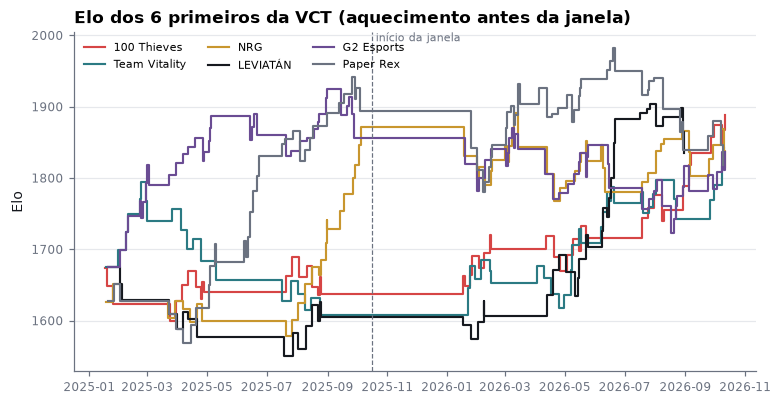

In [7]:
top = active[active.tier == "vct"].head(6)
hist = A.rating_history(con, top.team_id.tolist())
names = dict(zip(top.team_id, top.team_name))
start = pd.Timestamp(A.window(con)["first_match"])
fig, ax = plt.subplots(figsize=(8, 4))
palette = [P.ATTACK, P.DEFENSE, P.GOLD, P.INK, "#6a4c93", P.MUTED]
for color, (team, g) in zip(palette, hist.groupby("team_id", sort=False)):
    ax.step(g.match_at, g.rating_after, where="post", color=color, lw=1.4, label=names[team])
ax.axvline(start, color=P.MUTED, lw=0.8, ls="--")
ax.text(start, ax.get_ylim()[1], " início da janela", fontsize=7, color=P.MUTED, va="top")
ax.set_ylabel("Elo")
ax.set_title("Elo dos 6 primeiros da VCT (aquecimento antes da janela)")
ax.legend(ncols=3, fontsize=7)
plt.show()

## Conclusão

In [8]:
best = grid.iloc[0]
vct = active[active.tier == "vct"]
display(Markdown(f"""
- Busca em {len(grid)} combinações: o ótimo (K = {int(best.k)}, VCT {int(best.gap)} acima da VCL,
  carry {fmt(best.carry, 2)}, peso VCL {fmt(best.vcl_k_weight, 2)}, promoção
  {fmt(best.promotion_carry, 2)}) tem log loss {fmt(best.log_loss, 4)}; o padrão do projeto,
  {fmt(score(), 4)}; a moeda, {fmt(coin, 4)}. A diferença entre as dez melhores combinações é da
  ordem de 0,001: o resultado não depende de ajuste fino.
- Promoção: o time da VCL leva ao VCT {fmt(best.promotion_carry * 100, 0)}% do desvio que tinha na
  VCL. Dominar a VCL diz pouco sobre o VCT; nas séries entre quem veio da VCL e times do VCT, a
  log loss cai de {fmt(rows[2]['antes'], 3)} para {fmt(rows[2]['depois'], 3)}, com IC que ainda
  inclui zero ({rows[2]['séries']} séries).
- Topo da VCT na janela: {", ".join(vct.team_name.head(5))}.
- Os ranks por região × tier são a comparação honesta: entre circuitos, só os internacionais ligam
  as escalas (notebook 04).
"""))


- Busca em 1008 combinações: o ótimo (K = 48, VCT 300 acima da VCL,
  carry 0,75, peso VCL 1,00, promoção
  0,10) tem log loss 0,6630; o padrão do projeto,
  0,6630; a moeda, 0,6931. A diferença entre as dez melhores combinações é da
  ordem de 0,001: o resultado não depende de ajuste fino.
- Promoção: o time da VCL leva ao VCT 10% do desvio que tinha na
  VCL. Dominar a VCL diz pouco sobre o VCT; nas séries entre quem veio da VCL e times do VCT, a
  log loss cai de 0,727 para 0,707, com IC que ainda
  inclui zero (90 séries).
- Topo da VCT na janela: 100 Thieves, Team Vitality, G2 Esports, LEVIATÁN, Paper Rex.
- Os ranks por região × tier são a comparação honesta: entre circuitos, só os internacionais ligam
  as escalas (notebook 04).
